In the following, we want to define a geometry of a cascade case domain.
The domain should use profilepoints to define the shape of the airfoil.
In this case, the airfoil is generated using the naca_airfoil_creator function from ntrfc.

Lets start with importing all necessary modules

In [1]:
import pyvista as pv
import numpy as np
import os

from ntrfc.turbo.cascade_case.domain import CascadeDomain2DParameters, Blade2D
from ntrfc.turbo.cascade_case.domain import CascadeDomain2D
from ntrfc.turbo.airfoil_generators.naca_airfoil_creator import naca

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Lets set the jupyter backend for this jupyternotebook.
This is not necessary for the work in a normal shell

In [2]:
pv.set_jupyter_backend("static")

if os.getenv('DISPLAY') is None:
    pv.start_xvfb()  # Start X virtual framebuffer (Xvfb)

Define the profile points and define an alpha value for the alpha-shape of the airfoil

In [3]:
xs,ys = naca("6510",512)
points = pv.PolyData(np.stack([xs,ys,np.zeros(len(xs))]).T)
alpha = 1

In [4]:
blade = Blade2D(points)
blade.compute_all_frompoints(alpha=alpha)

working with pv.PolyData, dataarrays can be used for postprocessing


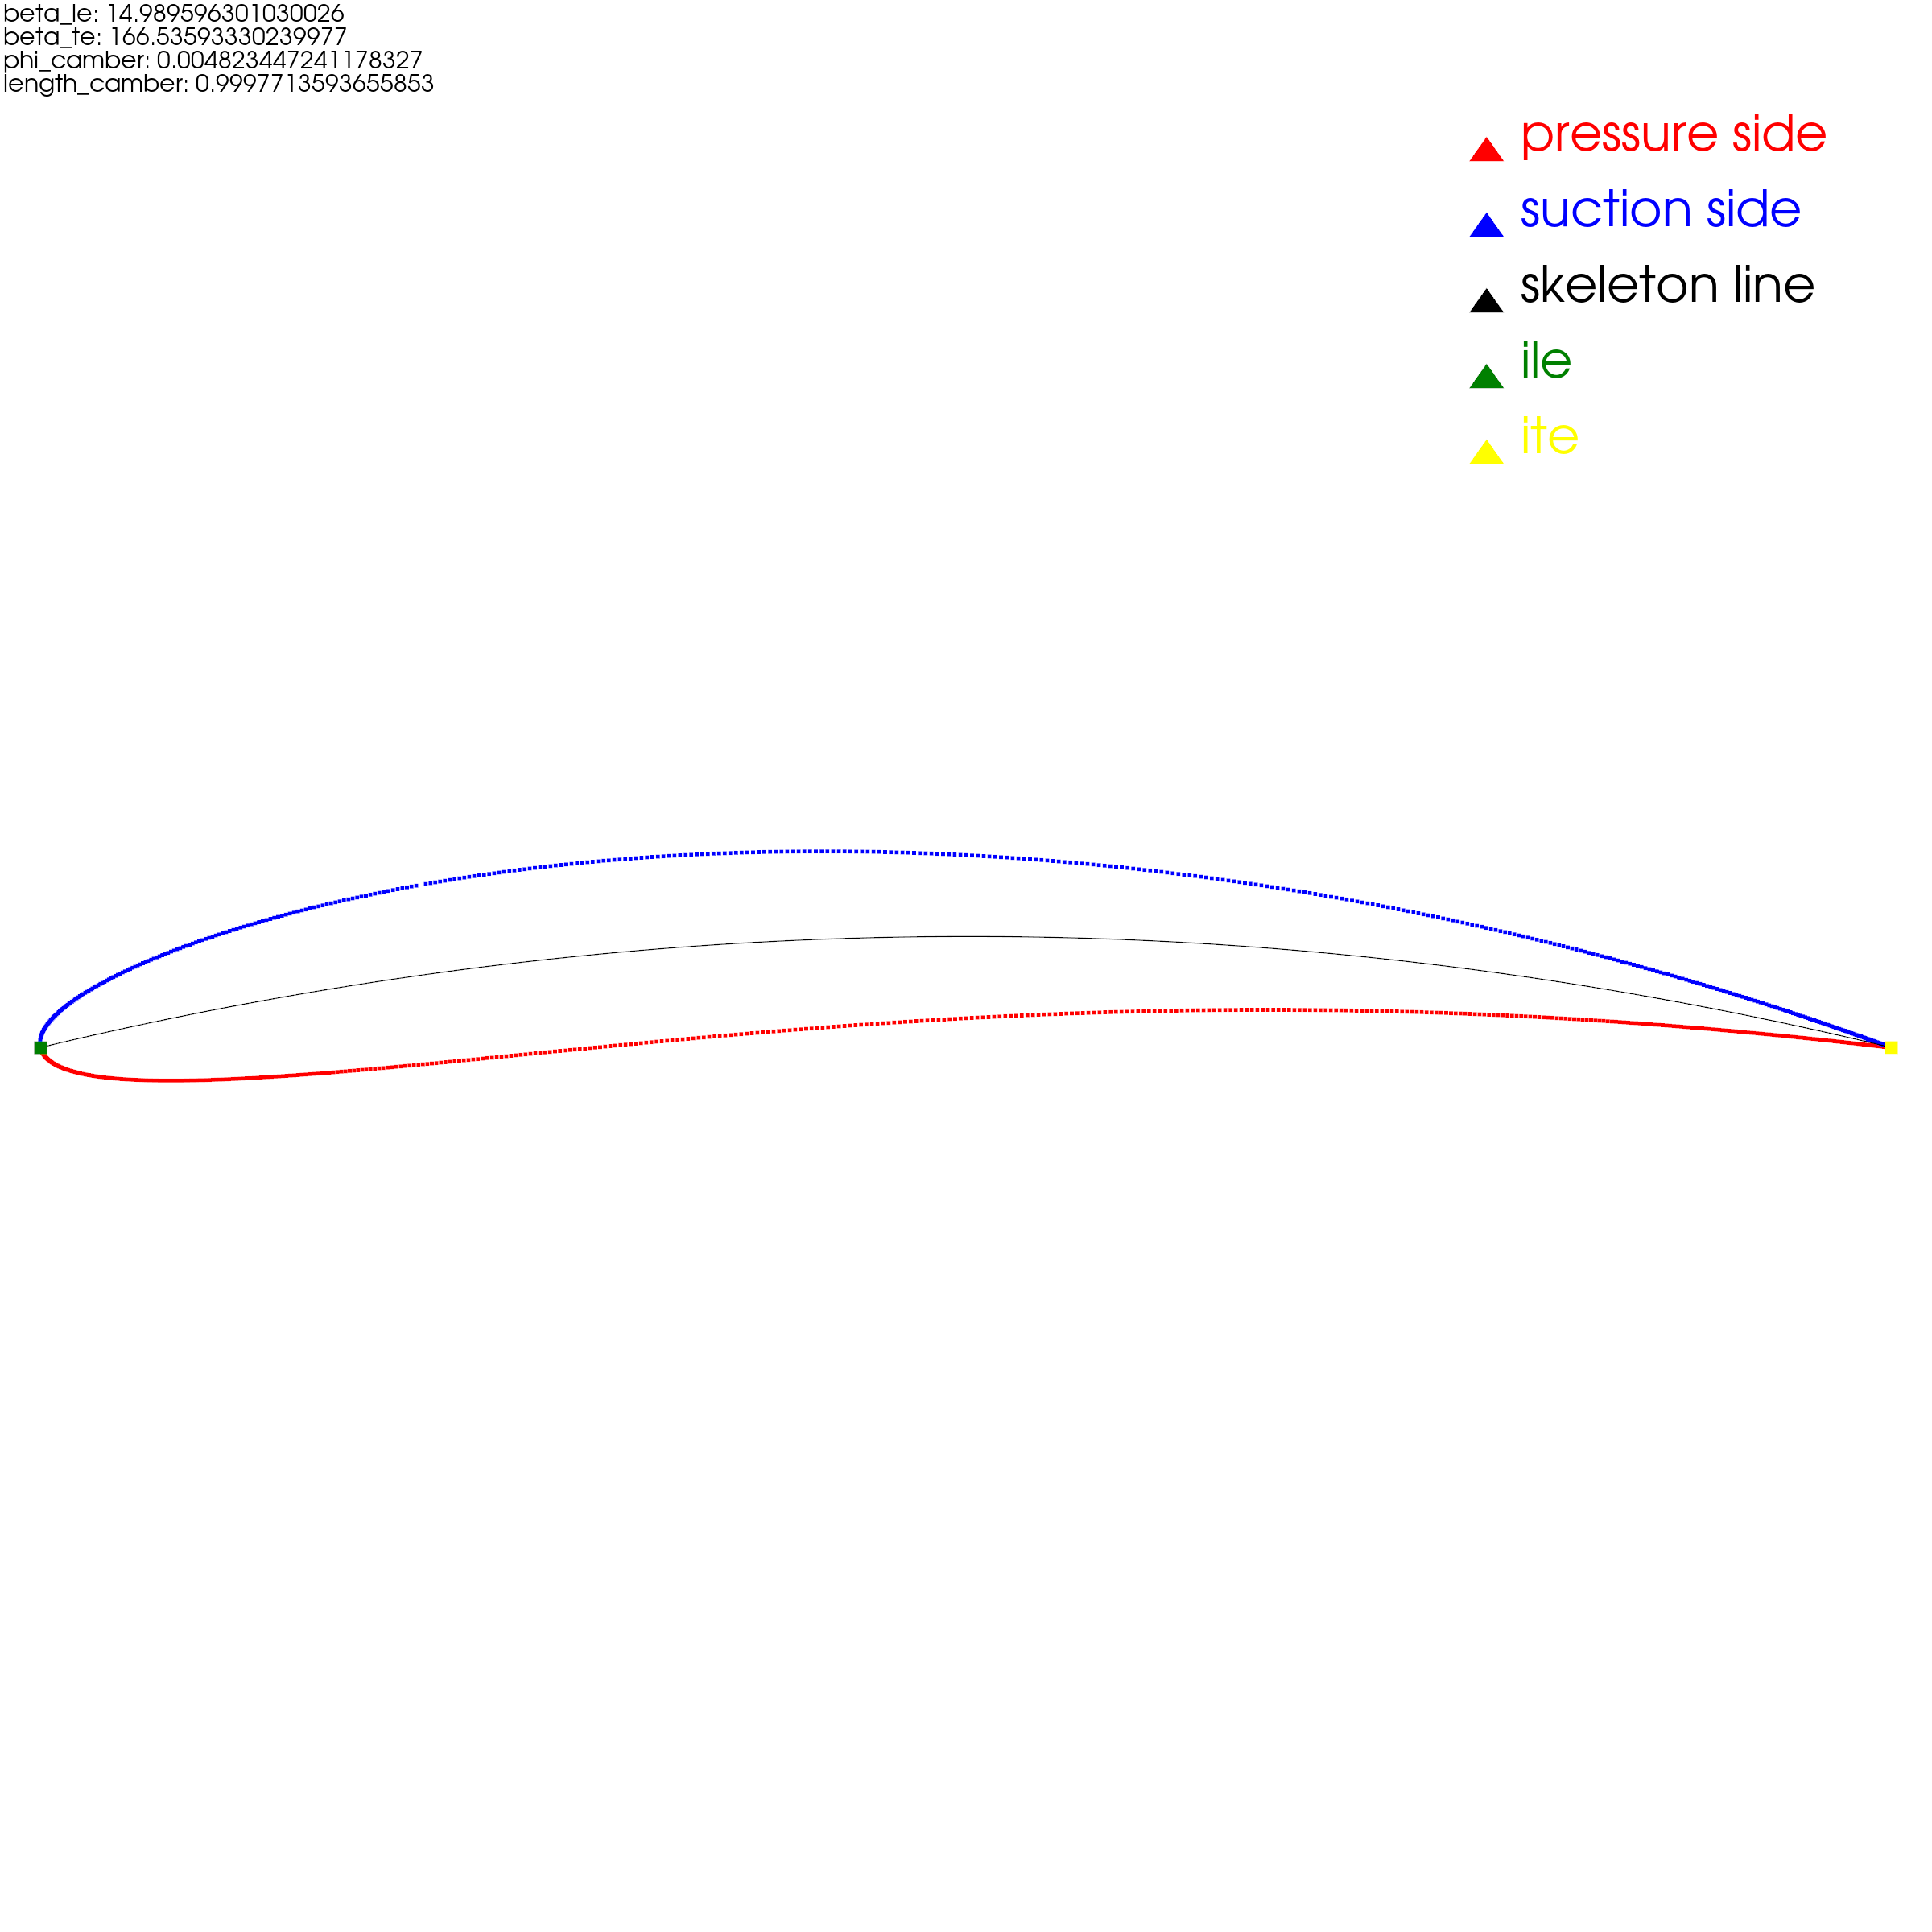

In [6]:
figpath = blade.plot()

Lets compute the airfoil and define domain parameters

In [7]:
domainparas = CascadeDomain2DParameters(xinlet=-1, xoutlet=2, pitch=1.3, blade_yshift=0.1)

You can define a domain with the CascadeDomain2D class and its method 'from_cascade_parameters'.
The Class has a plot-method which can be used to illustrate the domain.

In [8]:
domain2d = CascadeDomain2D()
domain2d.generate_from_cascade_parameters(domainparas,blade)

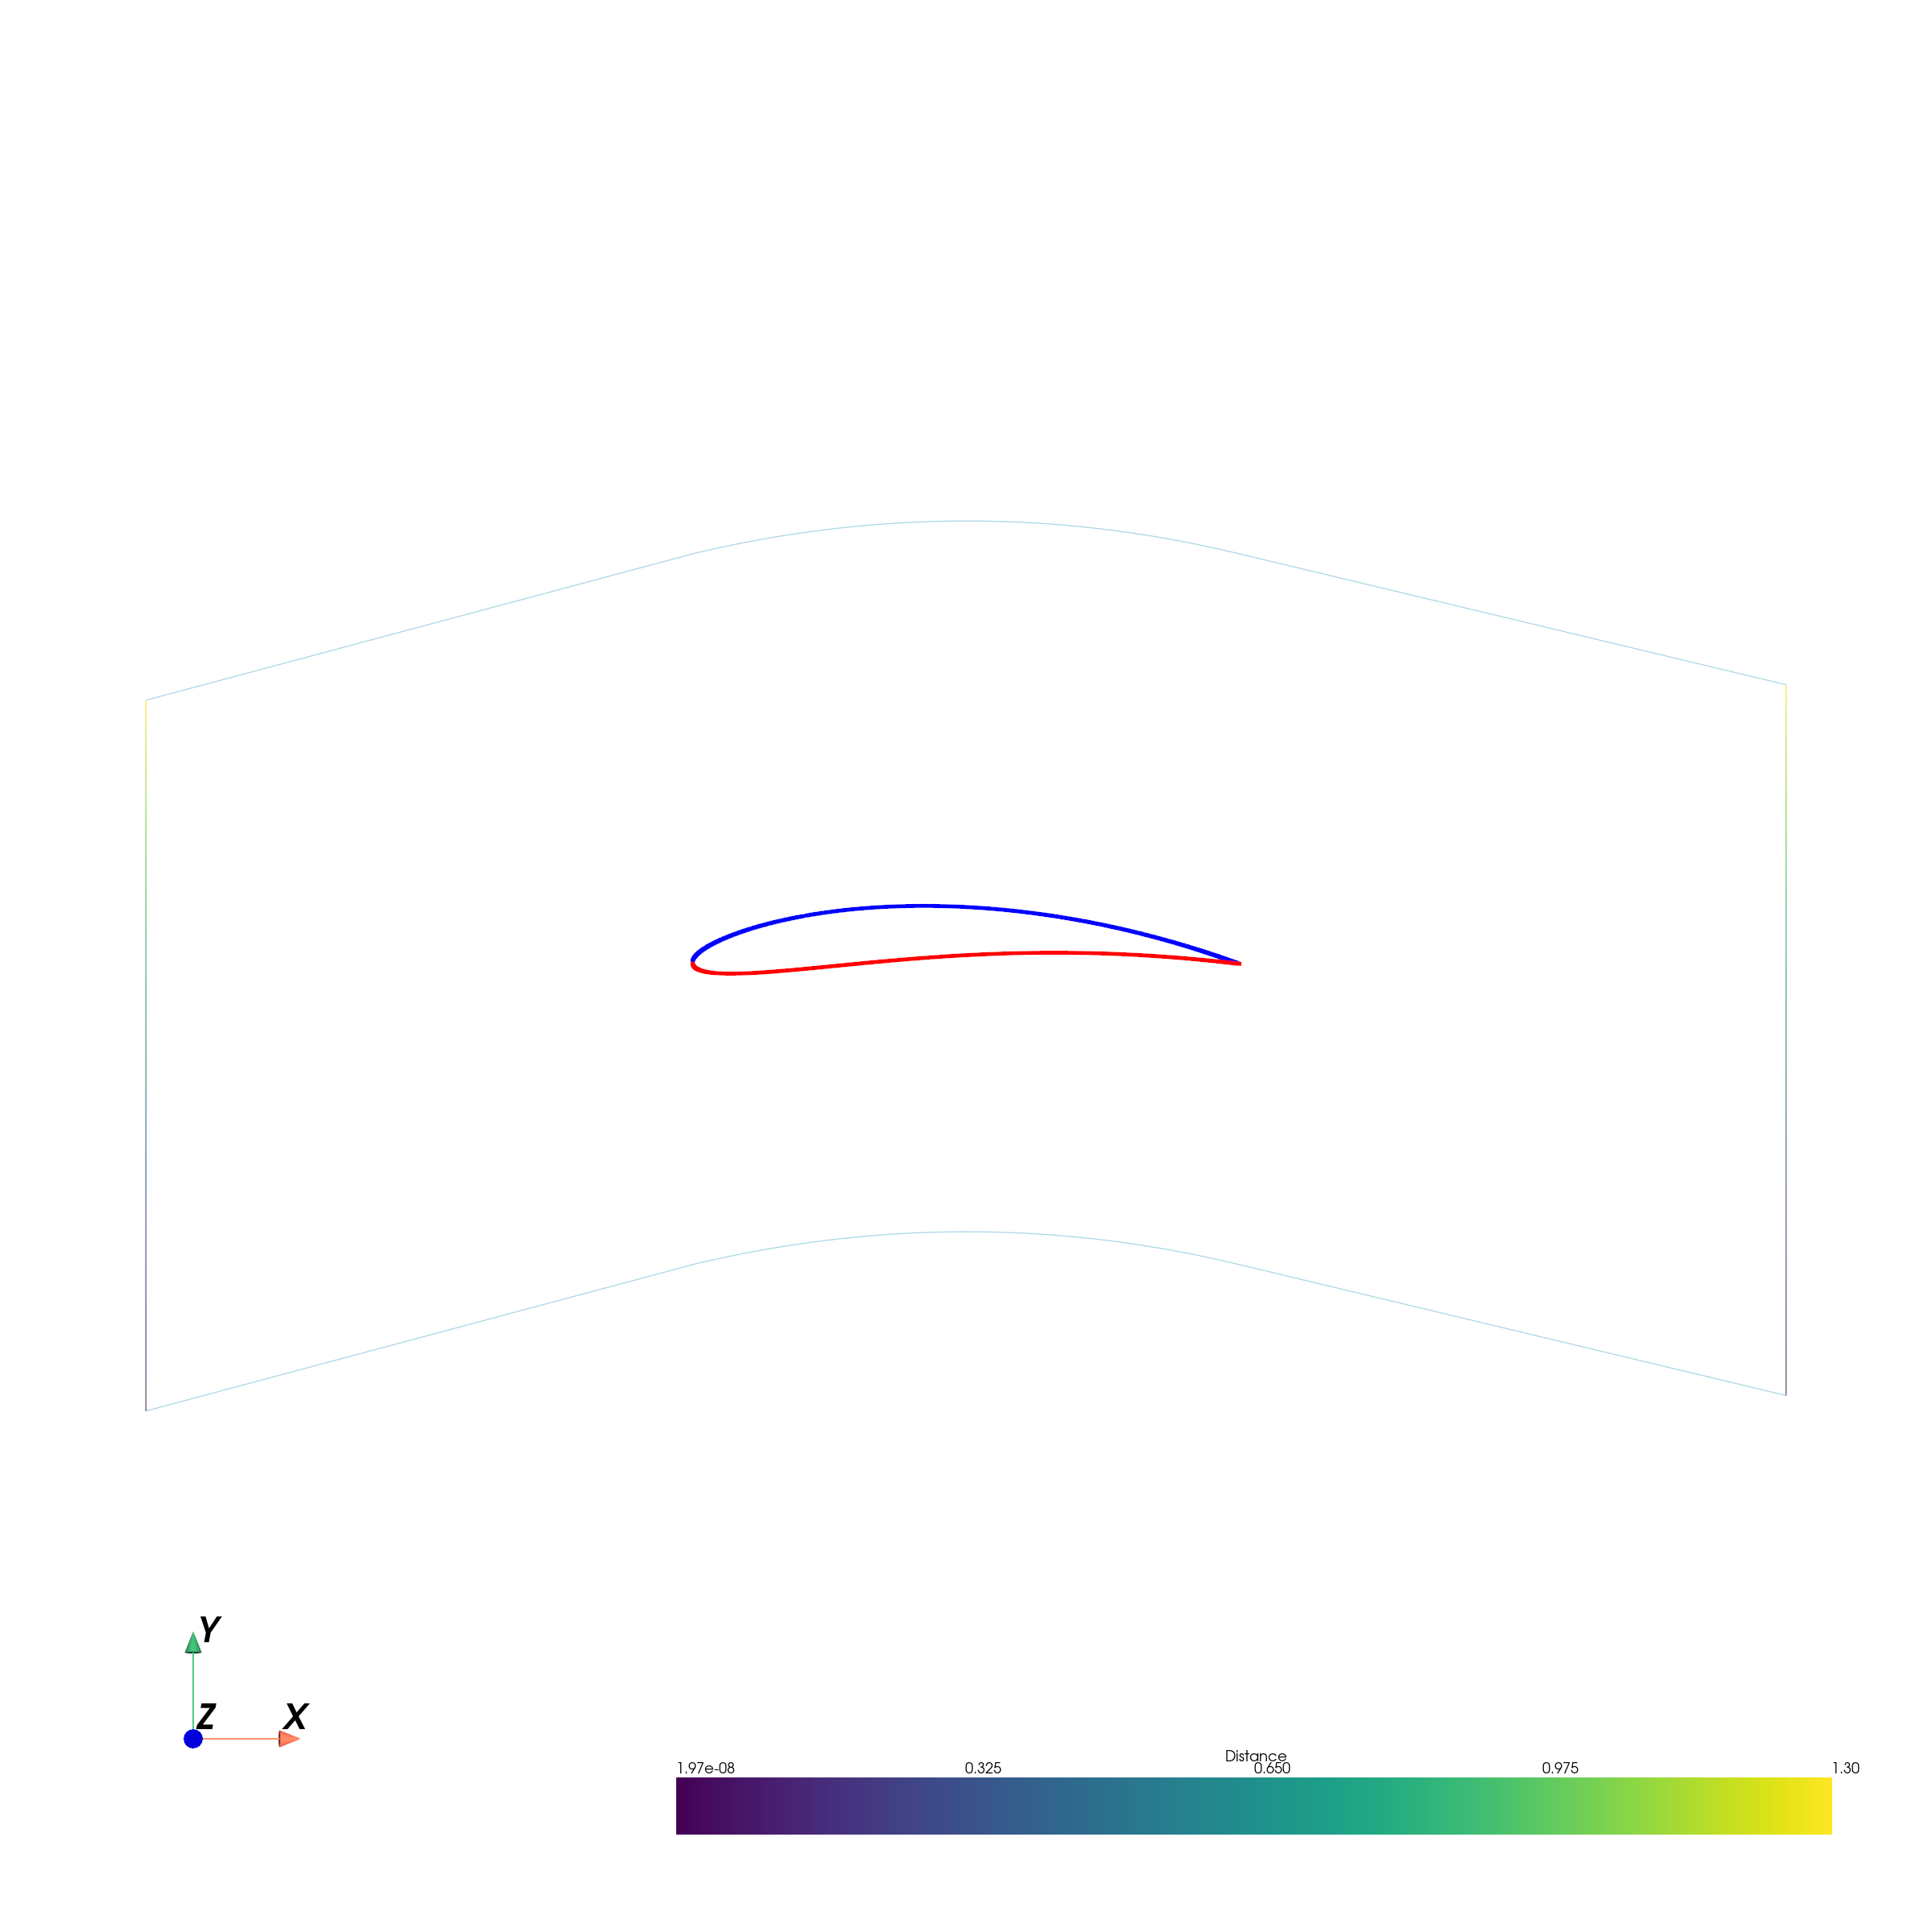

In [10]:
figpath = domain2d.plot_domain()
from IPython.display import Image
Image(figpath, width=400, height=400)
